# Hälsostudie - Del 1

## Läs in data

In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

df = pd.read_csv("data/health_study_dataset.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## Beskrivande statistik

In [5]:
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]
statistics = df[columns].describe()
statistics.loc[["mean", "50%", "min", "max"]]

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
50%,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


### Histogram över systoliskt blodtryck

Text(0, 0.5, 'Antal deltagare')

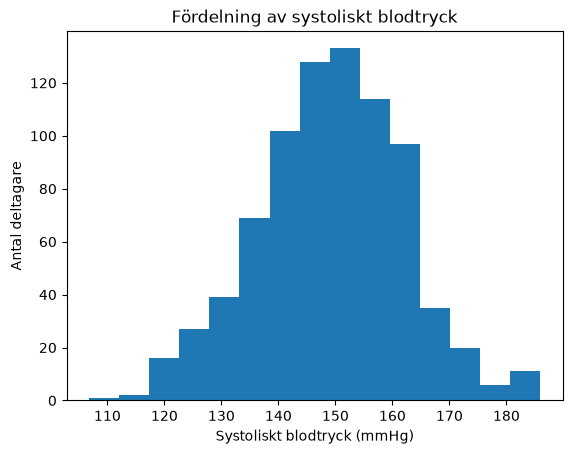

In [11]:
import matplotlib.pyplot as plt

plt.hist(df["systolic_bp"].dropna(), bins=15)
plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal deltagare")


### Boxplot över vikt per kön 

Text(0, 0.5, 'Vikt (kg)')

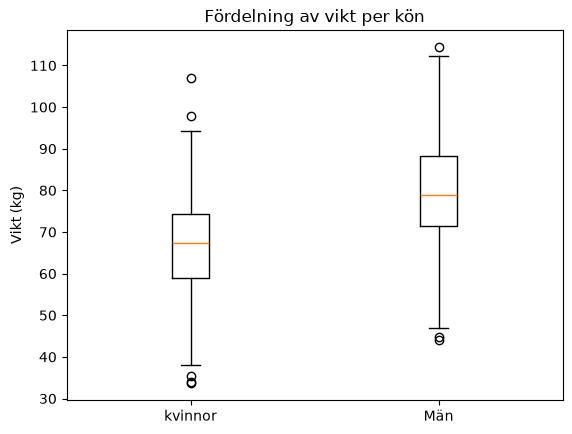

In [13]:
weight_f = df.loc[df["sex"] == "F", "weight"].dropna()
weight_m = df.loc[df["sex"] == "M", "weight"].dropna()

plt.boxplot([weight_f, weight_m])
plt.xticks([1, 2], ["kvinnor", "Män"])
plt.title("Fördelning av vikt per kön")
plt.ylabel("Vikt (kg)")

### Stapeldiagram över andelen rökare 

Text(0, 0.5, 'Andel (%)')

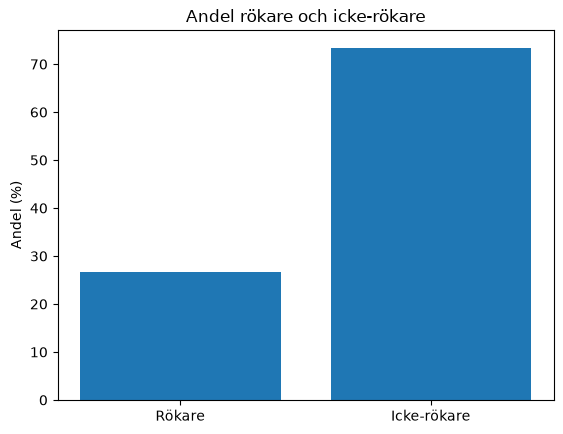

In [14]:
smoker_percent = df["smoker"].value_counts(normalize=True) * 100
plt.bar(["Rökare", "Icke-rökare"], [smoker_percent["Yes"], smoker_percent["No"]])
plt.title("Andel rökare och icke-rökare")
plt.ylabel("Andel (%)")

### Simulering av sjukdom

In [15]:
disease_share = df["disease"].mean()
print("Andel med sjukdom:", round(disease_share * 100, 2), "%")

Andel med sjukdom: 5.88 %


In [16]:
simulated_disease = np.random.binomial(1, disease_share, size = 1000)
simulated_share = simulated_disease.mean()

print("Simulerad andel med sjukdom:", round(simulated_share * 100, 2), "%")

Simulerad andel med sjukdom: 5.6 %


I datasetet hade 5,88 % sjukdomen.
I simuleringen var andelen 5,6 % . Det är cirka 0,28 procentenheter lägre.
Skillnaden kan bero på slumpen.

## Konfidensintervall för medelvärdet av systoliskt blodtryck

In [17]:
blood_pressure = df["systolic_bp"].dropna()
mean_bp = blood_pressure.mean()
standard_error = blood_pressure.std() / np.sqrt(len(blood_pressure))

lower = mean_bp - 1.96 * standard_error
upper = mean_bp + 1.96 * standard_error

print("95 % konfidensintervall:", round(lower, 2), "till", round(upper, 2), "mmHg")


95 % konfidensintervall: 148.29 till 150.07 mmHg


Med normalapproximation fick jag ett 95 % konfidensintervall från 148,29 till 150,07 mmHg.
Intervallet visar osäkerheten i uppskattningen av det genomsnittliga systoliska blodtrycket i populationen.

## Hypotesprövning - Blodtryck hos rökare och icke-rökare

In [19]:
bp_smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
bp_non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

print("Medeblodtryck för rökare: ", round(bp_smokers.mean(), 2), "mmHg")
print("Medelblodtryck för icke-rökare:", round(bp_non_smokers.mean(), 2), "mmHg")

Medeblodtryck för rökare:  149.52 mmHg
Medelblodtryck för icke-rökare: 149.05 mmHg
